<a href="https://colab.research.google.com/github/Hamdi-Jarban/--/blob/main/run_nerf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**bold إعداد البنية التحتية للبيانات وتحديد المعاييرtext**
**bold
lambda_l1: وزن خسارة L1 لضمان دقة البكسلات (100.0).
lambda_gan: وزن خسارة GAN الأساسية (1.0).
إدارة الحفظ: تحديد عدد مرات حفظ النموذج (كل 4 دورات) والحد الأقصى لعدد النسخ text**

In [ ]:
from torch.utils.data import DataLoader, Dataset
from dataclasses import dataclass
@dataclass
class ProjectConfig:
    size: int = 128
    latent_dim: int = 512
    batch_size: int = 16
    lr_g: float = 2e-4
    lr_d: float = 2e-4
    epochs: int = 50
    num_samples: int = 5000
    pos_enc_dims: int = 10
    lambda_l1: float = 100.0
    lambda_gan: float = 1.0
    save_frequency: int = 4
    sample_frequency: int = 10
    max_checkpoints: int = 5
    save_best_only: bool = True
    auto_cleanup: bool = True

**الأشكال المدعومة (5 أشكال):

Cube (المكعب): يُرسم باستخدام أسطح مستوية.

Sphere (الكرة): تُنشأ باستخدام إحداثيات قطبية.

Cone (المخروط): يُرسم بتدرج في نصف القطر.

Pyramid (الهرم): يُبنى برؤوس محددة يدويًا وأوجه مثلثية.

Torus (الطارة/الدونات): شكل هندسي حلقي معقد.**

boldآلية التوليد والرندرة (Rendering)
الدالة render: هي المسؤولة عن أخذ مواصفات الشكل

(النوع، اللون، زاوية الارتفاع elev، وزاوية السمت azim)
وتحويلها إلى صورة رقمية
(Pixel Matrix)
 بترميز RGBA ثم
 تحويلها إلى RGB وتطبيع قيم الألوان
 (Normalization) لتكون بين 0 و 1، وهو ما تحتاجه الشبكات العصبية.

الدالة get_sample: تقوم بتوليد "عينة تدريبية" كاملة تتكون من:

صورة للمجسم من زاوية عشوائية (Input Image).

صورة لنفس المجسم من زاوية عشوائية أخرى (Target Image).

متجهات رياضية تمثل الزوايا
(Parameters) لاستخدامها في حساب الخسارة (Loss Calculation) text


[OK] Setup complete. Saving to: content/working/geometric_models
Device: cuda
Training: 5000 samples x 50 epochs = 250,000 steps
5 Shapes with EDGE LINES (Cube, Sphere, Cone, Pyramid, Torus):
Total samples: 5000 images


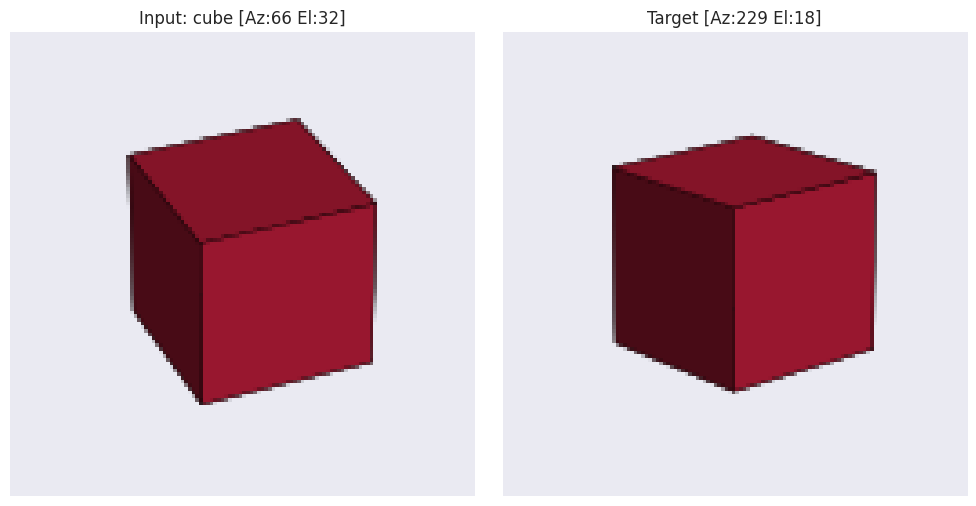

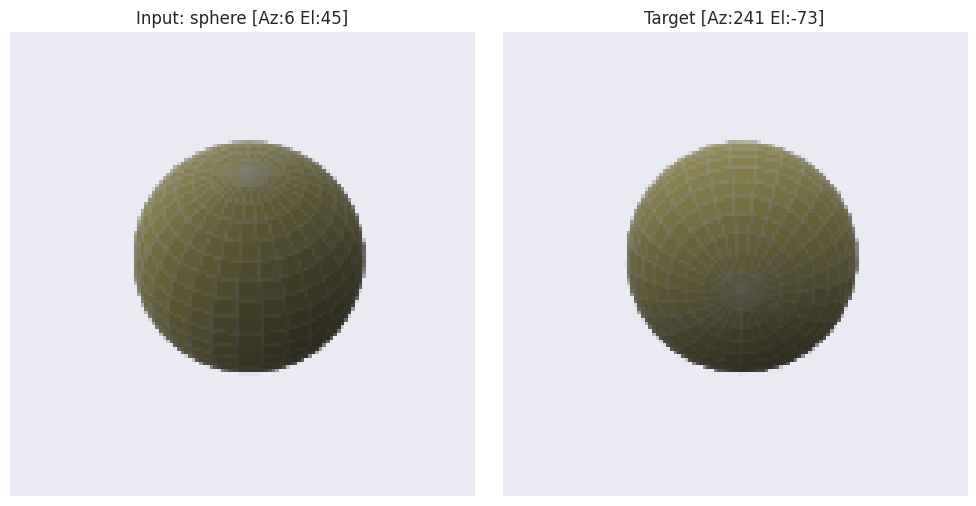

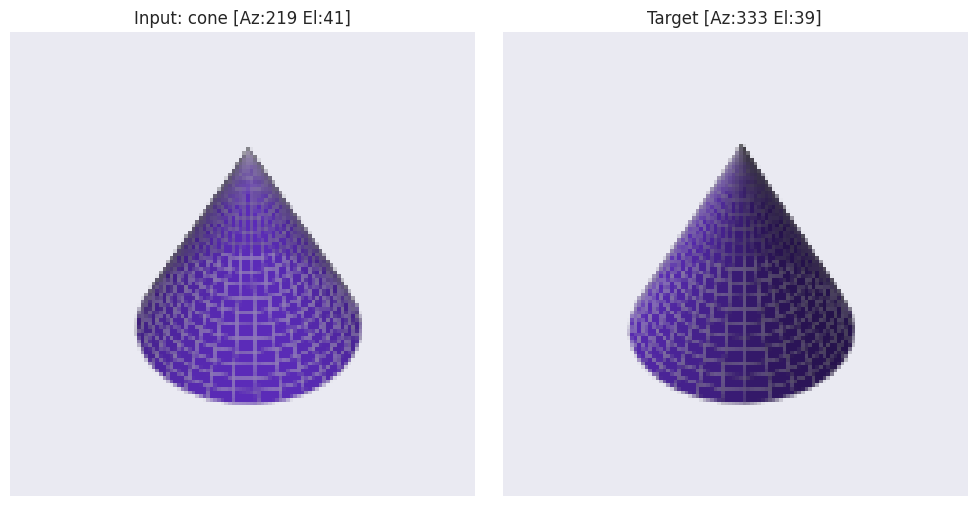

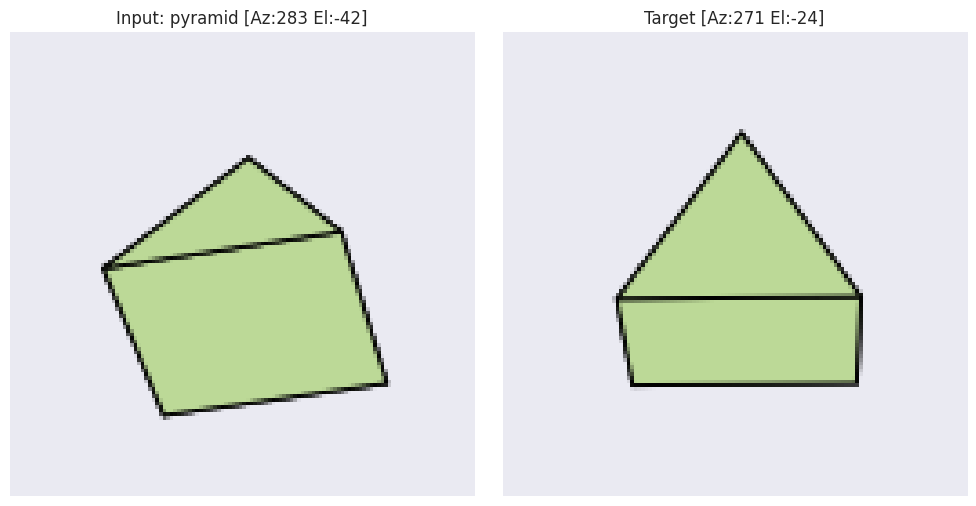

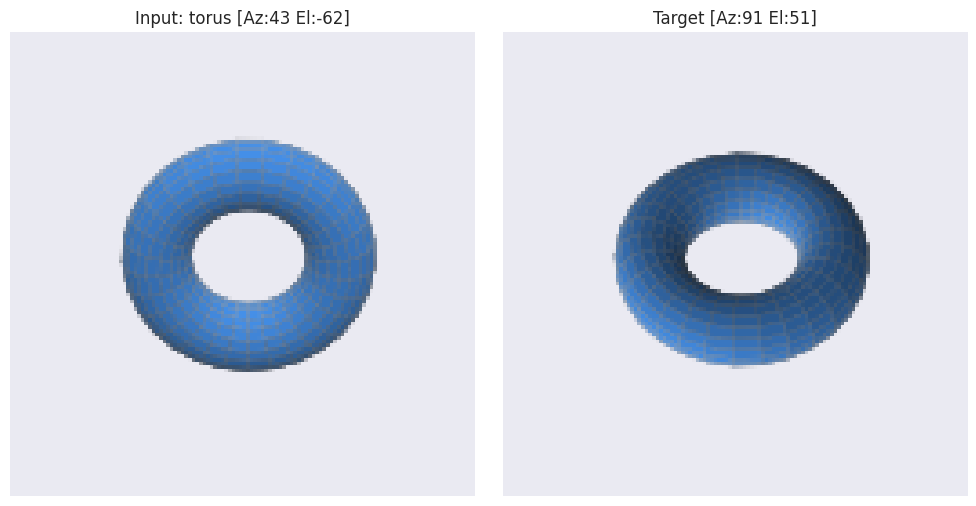

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np
import cv2
import random
from torchvision import models
import torch.nn.functional as F
from tqdm.notebook import tqdm
from IPython.display import clear_output

# KAGGLE SAVE PATH
SAVE_PATH = 'content/working/geometric_models'
os.makedirs(SAVE_PATH, exist_ok=True)
print(f"[OK] Setup complete. Saving to: {SAVE_PATH}")


config = ProjectConfig()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Training: {config.num_samples} samples x {config.epochs} epochs = {config.num_samples*config.epochs:,} steps")

class GeometryGenerator:
    """High-precision 3D shapes with EDGE LINES for better learning."""

    def __init__(self, size=128):
        self.image_size = (size, size)
        self.all_shapes = ['cube', 'sphere', 'cone', 'pyramid', 'torus']
        self.edge_color = 'black'
        self.edge_width = 0.3

    def _apply_style(self, ax):
        ax.set_box_aspect([1,1,1])
        ax.set_axis_off()
        limit = 0.6
        ax.set_xlim([-limit, limit])
        ax.set_ylim([-limit, limit])
        ax.set_zlim([-limit, limit])

    def _draw_cube(self, ax, color):
        r = [-0.4, 0.4]
        X, Y = np.meshgrid(r, r)
        for val in r:
            ax.plot_surface(X, Y, np.full_like(X, val), color=color, shade=True,
                           edgecolors=self.edge_color, linewidth=self.edge_width, antialiased=True)
            ax.plot_surface(X, np.full_like(X, val), Y, color=color, shade=True,
                           edgecolors=self.edge_color, linewidth=self.edge_width, antialiased=True)
            ax.plot_surface(np.full_like(X, val), X, Y, color=color, shade=True,
                           edgecolors=self.edge_color, linewidth=self.edge_width, antialiased=True)

    def _draw_sphere(self, ax, color):
        u, v = np.mgrid[0:2*np.pi:30j, 0:np.pi:20j]
        x = 0.5*np.cos(u)*np.sin(v)
        y = 0.5*np.sin(u)*np.sin(v)
        z = 0.5*np.cos(v)
        ax.plot_surface(x, y, z, color=color, shade=True,
                       edgecolors='darkgray', linewidth=0.2, antialiased=True)

    def _draw_cone(self, ax, color):
        z = np.linspace(-0.4, 0.6, 20)
        theta = np.linspace(0, 2*np.pi, 30)
        theta_grid, z_grid = np.meshgrid(theta, z)
        radius = (0.6 - z_grid) * 0.5
        ax.plot_surface(radius*np.cos(theta_grid), radius*np.sin(theta_grid), z_grid, color=color, shade=True,
                       edgecolors='darkgray', linewidth=0.2, antialiased=True)

    def _draw_pyramid(self, ax, color):
        v = np.array([[-0.5, -0.5, -0.4], [0.5, -0.5, -0.4], [0.5, 0.5, -0.4], [-0.5, 0.5, -0.4], [0, 0, 0.6]])
        faces = [[v[0],v[1],v[4]], [v[1],v[2],v[4]], [v[2],v[3],v[4]], [v[3],v[0],v[4]], [v[0],v[1],v[2],v[3]]]
        ax.add_collection3d(Poly3DCollection(faces, facecolors=color, edgecolors='black', linewidths=1.0, antialiased=True))

    def _draw_torus(self, ax, color):
        u, v = np.mgrid[0:2*np.pi:30j, 0:2*np.pi:20j]
        R, r = 0.4, 0.15
        x = (R + r*np.cos(v)) * np.cos(u)
        y = (R + r*np.cos(v)) * np.sin(u)
        z = r * np.sin(v)
        ax.plot_surface(x, y, z, color=color, shade=True, edgecolors='darkgray', linewidth=0.2, antialiased=True)

    def render(self, shape_type, color, azim, elev):
        dpi = 72
        figsize = (self.image_size[0]/dpi, self.image_size[1]/dpi)
        fig = plt.figure(figsize=figsize, dpi=dpi)
        ax = fig.add_subplot(111, projection='3d')
        draw_func = getattr(self, f'_draw_{shape_type}', None)
        if draw_func: draw_func(ax, color)
        self._apply_style(ax)
        ax.view_init(elev=elev, azim=azim)
        plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
        fig.canvas.draw()
        img = np.asarray(fig.canvas.buffer_rgba())[:, :, :3]
        plt.close(fig)
        if img.shape[:2] != self.image_size: img = cv2.resize(img, self.image_size)
        return img.astype(np.float32) / 255.0

    def get_sample(self, i=None, n=55000):
        shape_list = self.all_shapes
        if i is not None:
            shape_idx = (i // (max(1, n // len(shape_list)))) % len(shape_list)
            name = shape_list[shape_idx]
            color = (0.5 + 0.3 * np.cos(shape_idx), 0.5 + 0.3 * np.sin(shape_idx), 0.7)
            samples_per_shape = max(1, n // len(shape_list))
            local_idx = i % samples_per_shape
            azim_in = (local_idx * 73.0) % 360.0
            elev_in = (local_idx * 19.0) % 180.0 - 90.0
            azim_tgt = random.uniform(0, 360)
            elev_tgt = random.uniform(-90, 90)
        else:
            name = random.choice(shape_list)
            color = tuple(np.random.rand(3))
            azim_in = random.uniform(0, 360)
            elev_in = random.uniform(-90, 90)
            azim_tgt = random.uniform(0, 360)
            elev_tgt = random.uniform(-90, 90)
        img_in = self.render(name, color, azim_in, elev_in)
        img_tgt = self.render(name, color, azim_tgt, elev_tgt)
        p_in = np.array([1.0, azim_in/360.0, elev_in/180.0], dtype=np.float32)
        p_tg = np.array([1.0, azim_tgt/360.0, elev_tgt/180.0], dtype=np.float32)
        return img_in, img_tgt, p_in, p_tg, name

    def generate_and_show(self, shape_name):
        color = tuple(np.random.rand(3))
        azim_in, elev_in = random.uniform(0, 360), random.uniform(-90, 90)
        img_in = self.render(shape_name, color, azim_in, elev_in)
        azim_tgt, elev_tgt = random.uniform(0, 360), random.uniform(-90, 90)
        img_tgt = self.render(shape_name, color, azim_tgt, elev_tgt)
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img_in); axes[0].set_title(f"Input: {shape_name} [Az:{azim_in:.0f} El:{elev_in:.0f}]"); axes[0].axis('off')
        axes[1].imshow(img_tgt); axes[1].set_title(f"Target [Az:{azim_tgt:.0f} El:{elev_tgt:.0f}]"); axes[1].axis('off')
        plt.tight_layout(); plt.show()

generator = GeometryGenerator(size=128)
print("5 Shapes with EDGE LINES (Cube, Sphere, Cone, Pyramid, Torus):")
print(f"Total samples: {config.num_samples} images")
generator.generate_and_show('cube')
generator.generate_and_show('sphere')
generator.generate_and_show('cone')
generator.generate_and_show('pyramid')
generator.generate_and_show('torus')

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import numpy as np
import os
from dataclasses import dataclass

@dataclass
class ProjectConfig:
    size: int = 128
    latent_dim: int = 512
    batch_size: int = 16
    lr_g: float = 2e-4
    lr_d: float = 2e-4
    epochs: int = 100
    num_samples: int = 5000
    pos_enc_dims: int = 10
    lambda_l1: float = 100.0
    lambda_gan: float = 1.0
    start_epoch: int = 40
    save_frequency: int = 5

config = ProjectConfig()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SAVE_PATH = './checkpoints'
os.makedirs(SAVE_PATH, exist_ok=True)


#  تحليل فئة الترميز الموضعي `PositionalEncoding`

تُعد هذه الطبقة مكوناً جوهرياً في معمارية النموذج، حيث تعمل على تحويل المدخلات الرقمية البسيطة (مثل زوايا الكاميرا) إلى تمثيل هندسي غني بالترددات.

###  الفلسفة الرياضية
الشبكات العصبية تميل لتعلم الوظائف "السلسة" (Low-frequency) وتواجه صعوبة في التقاط التغيرات الحادة. من خلال تطبيق دالات الجيب والتمام بترددات متزايدة، نقوم بعمل **Spectral Mapping** يسمح للنموذج بالتمييز بين الزوايا المتقاربة جداً.



###  آلية العمل (Mechanism)
تقوم الدالة بتوسيع كل قيمة مدخلة $x$ وفق المعادلة التالية:
$$PE(x) = \left( x, \sin(2^0 \pi x), \cos(2^0 \pi x), \dots, \sin(2^{L-1} \pi x), \cos(2^{L-1} \pi x) \right)$$
*حيث $L$ يمثل `num_frequencies`.*

---

###  هيكلية البيانات (Data Dimensions)

| الخاصية | القيمة | الوصف |
| :--- | :--- | :--- |
| **Input Dimensions** | `12` | مصفوفة الكاميرا المسطحة ($3 \times 4$) |
| **Number of Frequencies** | `3` | عدد مستويات التردد ($2^0, 2^1, 2^2$) |
| **Total Components** | `7` | القيمة الأصلية + (Sin و Cos لكل تردد) |
| **Final Output Dim** | **`84`** | الناتج النهائي ($12 \times 7$) |

---



In [ ]:

class PositionalEncoding(nn.Module):
    def __init__(self, input_dim=12, num_frequencies=3):
        super().__init__()
        self.num_frequencies = num_frequencies
        self.input_dim = input_dim

    def forward(self, x):
        out = [x]
        for i in range(self.num_frequencies):
            for func in [torch.sin, torch.cos]:
                out.append(func(2**i * np.pi * x))
        return torch.cat(out, dim=-1)

    def get_output_dim(self):
        return self.input_dim * (2 * self.num_frequencies + 1)

###  كتلة التعلم المتبقي (Residual Block)

تُعرف علمياً بـ **Residual Block**، وهي المحرك الأساسي لشبكات **ResNet**. تكمن قوتها في استخدام **"الوصلات المختصرة" (Skip Connections)** لحل مشكلة تلاشي التدرجات.



**💡 المفهوم الرياضي:**
بدلاً من تعلم وظيفة معقدة، تتعلم الكتلة **الفرق (Residual)** بين المدخل والمخرج وفق المعادلة:
$$y = F(x) + x$$

** هيكلية الكتلة:**
1. **المسار الرئيسي:** تلافيف (Conv) ⬅️ تسوية (BN) ⬅️ تنشيط (ReLU).
2. **المسار المختصر:** يمرر المدخلات كما هي ليتم جمعها في النهاية.
3. **التعديل (Downsample):** يضبط الأبعاد إذا اختلف حجم المدخل عن المخرج.

** الفائدة:** تسمح بتدريب شبكات عميقة جداً مع الحفاظ على استقرار تدفق المعلومات.

In [ ]:

class BasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(planes, planes, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.downsample = downsample

    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return self.relu(out)


##  وحدة المولد: محرك التخليق الصوري (The Generator)
يعمل هذا الجزء كـ **Renderer** عصبي يقوم بتحويل الصورة من زاوية رؤية إلى أخرى. يعتمد التصميم على معمارية **Encoder-Decoder** هجينة تدمج بين المعلومات البصرية والمعلومات الهندسيّة للكاميرا.
1. **ResNet-34 Encoder:** استخراج الميزات العميقة من الصورة المدخلة وتحويلها إلى تمثيل رياضي مضغوط.
2. **Positional Encoding:** تشفير زوايا الكاميرا (Source & Target) إلى ترددات عالية لمساعدة الشبكة على فهم الفروقات الدقيقة في الدوران.
3. **Camera MLP:** شبكة دمج تقوم بربط ميزات الشكل (Visual) بميزات الحركة (Camera Pose) لتوجيه عملية التوليد.
4. **Skip-Connection Decoder:** بناء الصورة الهدف تدريجياً مع استرجاع التفاصيل الدقيقة من الطبقات الأولى للمشفر لضمان حدة الحواف (Sharp Edges).


In [ ]:

class Generator(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.resnet = ResNet34Like()

        # Positional Encoding - input_dim=12, num_frequencies=3 => 84
        self.pos_encoder = PositionalEncoding(input_dim=12, num_frequencies=3)
        enc_dim = self.pos_encoder.get_output_dim()  # 84

        print(f"[INFO] PositionalEncoding output dim: {enc_dim}")

        # Camera MLP - المدخل 168 (84*2)
        self.cam_mlp = nn.Sequential(
            nn.Linear(enc_dim * 2, 256),  # 168 -> 256
            nn.ReLU(),
            nn.Linear(256, config.latent_dim)  # 256 -> 512
        )

        self.decoder_input = nn.Linear(config.latent_dim + 512, 512 * 4 * 4)  # 1024 -> 8192

        # Up blocks
        self.up1 = self._up_block(512 + 512, 256)  # 1024 -> 256, 4x4 -> 8x8
        self.up2 = self._up_block(256 + 256, 128)  # 512 -> 128, 8x8 -> 16x16
        self.up3 = self._up_block(128 + 128, 64)   # 256 -> 64, 16x16 -> 32x32
        self.up4 = self._up_block(64 + 64, 32)     # 128 -> 32, 32x32 -> 64x64
        self.up5 = self._up_block(32, 16)          # 32 -> 16, 64x64 -> 128x128

        self.final_conv = nn.Sequential(
            nn.Conv2d(16, 3, 3, 1, 1),
            nn.Sigmoid()
        )

    def _up_block(self, i, o):
        return nn.Sequential(
            nn.ConvTranspose2d(i, o, 4, 2, 1),
            nn.InstanceNorm2d(o),
            nn.ReLU(True)
        )

    def forward(self, img, src, tgt):
        # Encoder
        x0, x1, x2, x3, x4, pooled = self.resnet(img)

        src_flat = src.view(src.shape[0], -1)  # [B, 12]
        tgt_flat = tgt.view(tgt.shape[0], -1)  # [B, 12]
        src_enc = self.pos_encoder(src_flat)  # [B, 84]
        tgt_enc = self.pos_encoder(tgt_flat)  # [B, 84]

        # Concat كما في النموذج المحفوظ
        cam_concat = torch.cat([src_enc, tgt_enc], dim=1)  # [B, 168]

        # Camera MLP
        cam_feat = self.cam_mlp(cam_concat)  # [B, 512]

        # Decoder
        d = self.decoder_input(torch.cat([pooled, cam_feat], dim=1))
        d = d.view(-1, 512, 4, 4)

        d = self.up1(torch.cat([d, x4], dim=1))
        d = self.up2(torch.cat([d, x3], dim=1))
        d = self.up3(torch.cat([d, x2], dim=1))
        d = self.up4(torch.cat([d, x1], dim=1))
        d = self.up5(d)

        return self.final_conv(d)


##  وحدة المميز: ناقد الجودة (The Discriminator)
شبكة **PatchGAN** تقوم بتحليل الصورة الأصلية والمولدة معاً لتقييم واقعية التفاصيل والحواف.
تعتمد على طبقات تلافيفية متكررة (Blocks) لتقليل الأبعاد وإصدار خريطة قرار (Decision Map) تحدد المناطق الحقيقية والمزيفة.

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            self._block(6, 64, 4, 2, 1, False),  # 128 -> 64
            self._block(64, 128, 4, 2, 1),       # 64 -> 32
            self._block(128, 256, 4, 2, 1),      # 32 -> 16
            self._block(256, 512, 4, 2, 1),      # 16 -> 8
            self._block(512, 512, 4, 2, 1),      # 8 -> 4
            nn.Conv2d(512, 1, 4, 1, 1)           # 4 -> 1? في النموذج المحفوظ كان 4 -> 1?
        )

    def _block(self, i, o, k, s, p, norm=True):
        layers = [nn.Conv2d(i, o, k, s, p)]
        if norm:
            layers.append(nn.InstanceNorm2d(o))
        layers.append(nn.LeakyReLU(0.2, True))
        return nn.Sequential(*layers)

    def forward(self, a, b):
        return self.model(torch.cat([a, b], dim=1))


##  وحدة البيانات: مُجهز العينات (The Dataset)
كلاس يقوم بربط المولد الهندسي ببيئة PyTorch لتحميل ومعالجة الصور والزوايا وتجهيزها في دفعات (Batches).
يتولى تحويل الصور إلى Tensors وتوحيد أبعادها (Resizing) مع تطبيع قيم البكسلات لتسريع عملية تدريب النموذج.

In [ ]:

class GeometryDataset(Dataset):
    def __init__(self, gen, n, size=128):
        self.gen = gen
        self.n = n
        self.size = size

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        img_in, img_tg, p_in, p_tg, _ = self.gen.get_sample(i, self.n)

        img_in = torch.from_numpy(img_in).permute(2, 0, 1).float() / 255.0
        img_tg = torch.from_numpy(img_tg).permute(2, 0, 1).float() / 255.0

        # تغيير الحجم إذا لزم الأمر
        if img_in.shape[1] != self.size:
            img_in = F.interpolate(img_in.unsqueeze(0), size=(self.size, self.size),
                                 mode='bilinear', align_corners=False).squeeze(0)
            img_tg = F.interpolate(img_tg.unsqueeze(0), size=(self.size, self.size),
                                 mode='bilinear', align_corners=False).squeeze(0)

        return img_in, img_tg, torch.from_numpy(p_in).float(), torch.from_numpy(p_tg).float()


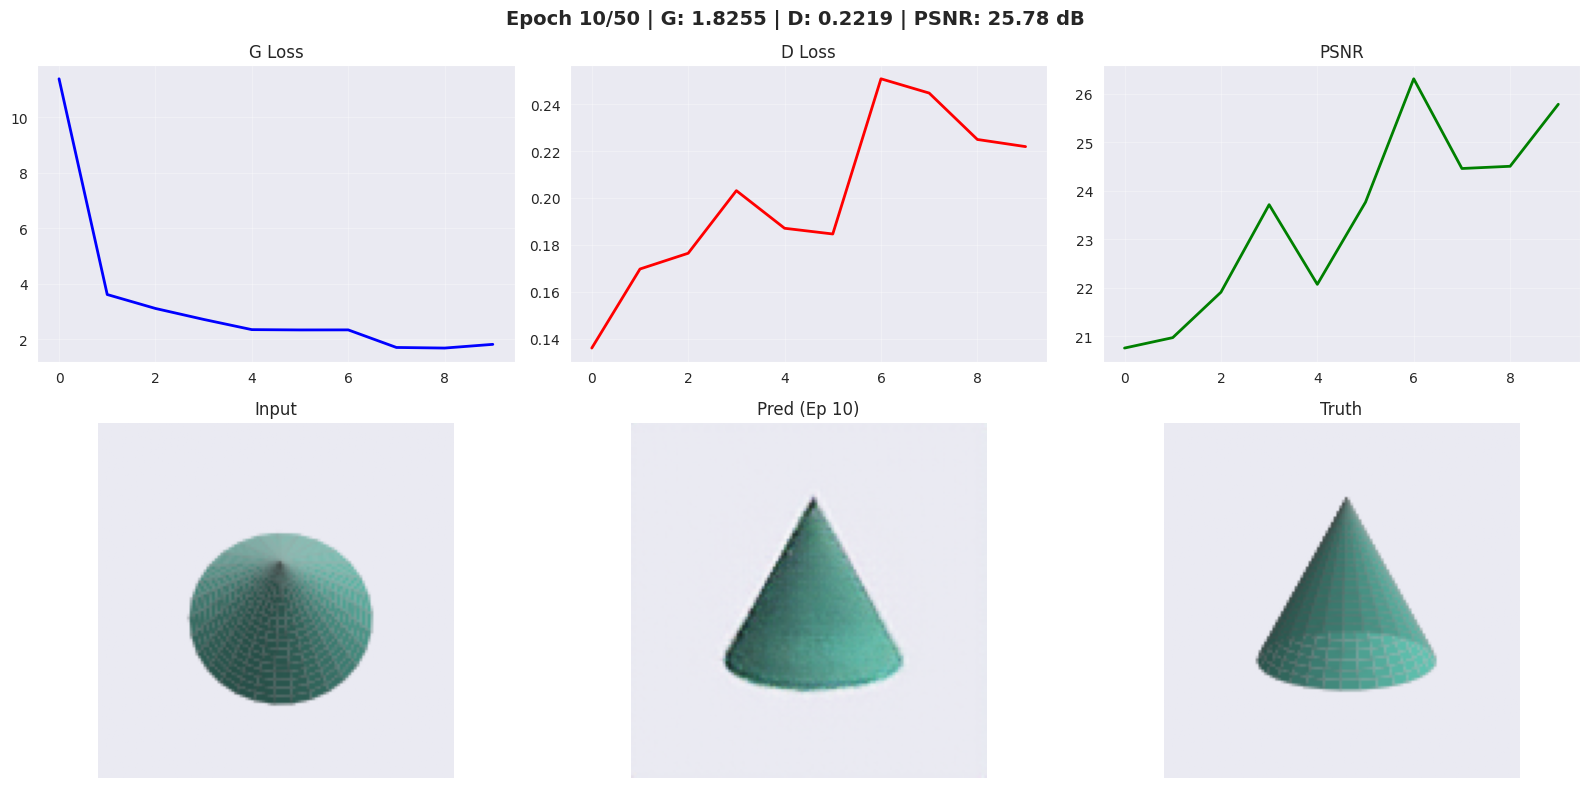

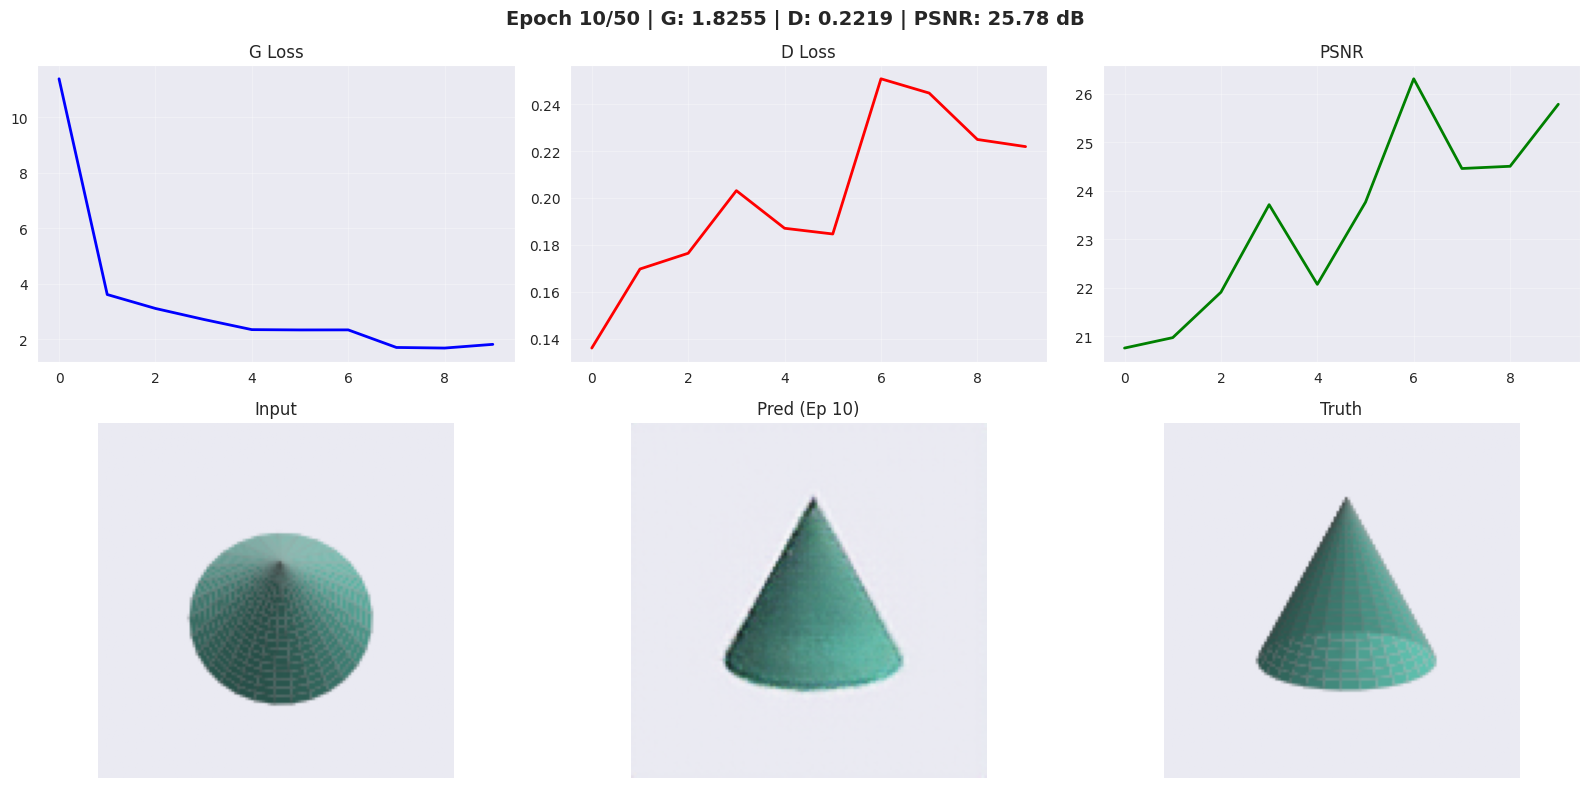

In [ ]:

def train_gan():
    print("=" * 60)
    print(f"🚀 Starting training on {device}")
    print(f"   Image size: {config.size}x{config.size}")
    print(f"   Starting from epoch: {config.start_epoch}")
    print("=" * 60)
    try:
        from __main__ import GeometryGenerator
        gen_obj = GeometryGenerator(size=config.size)
        print("✅ GeometryGenerator loaded")
    except ImportError:
        print("❌ GeometryGenerator not found")
        return
    generator = Generator(config).to(device)
    discriminator = Discriminator().to(device)
    test_input = torch.randn(1, 3, config.size, config.size).to(device)
    test_output = discriminator(test_input, test_input)
    print(f"\n[INFO] Discriminator output shape: {test_output.shape}")
    generator_path = os.path.join(SAVE_PATH, 'generator_gan.pth')
    if os.path.exists(generator_path):
        print("\n📂 Loading generator weights...")
        state_dict = torch.load(generator_path, map_location=device)
        model_dict = generator.state_dict()
        loaded_count = 0
        for key, value in state_dict.items():
            if key in model_dict and value.shape == model_dict[key].shape:
                model_dict[key] = value
                loaded_count += 1
        generator.load_state_dict(model_dict, strict=False)
        print(f"✅ Loaded {loaded_count} generator weights")

    discriminator_path = os.path.join(SAVE_PATH, 'discriminator_gan.pth')
    if os.path.exists(discriminator_path):
        print("\n📂 Loading discriminator weights...")
        disc_state_dict = torch.load(discriminator_path, map_location=device)
        disc_model_dict = discriminator.state_dict()
        disc_loaded = 0
        for key, value in disc_state_dict.items():
            if key in disc_model_dict and value.shape == disc_model_dict[key].shape:
                disc_model_dict[key] = value
                disc_loaded += 1
        discriminator.load_state_dict(disc_model_dict, strict=False)
        print(f"✅ Loaded {disc_loaded} discriminator weights")
    opt_g = optim.Adam(generator.parameters(), lr=config.lr_g, betas=(0.5, 0.999))
    opt_d = optim.Adam(discriminator.parameters(), lr=config.lr_d, betas=(0.5, 0.999))
    criterion_gan = nn.MSELoss()
    criterion_l1 = nn.L1Loss()
    dataset = GeometryDataset(gen_obj, config.num_samples, config.size)
    loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=True, drop_last=True)
    test_batch = next(iter(loader))
    test_img, test_tg, test_p_in, test_p_tg = [x.to(device) for x in test_batch]

    print("\n🧪 Testing forward pass...")
    with torch.no_grad():
        test_out = generator(test_img[:1], test_p_in[:1], test_p_tg[:1])
        print(f"  ✅ Generator forward pass successful! Output shape: {test_out.shape}")
        test_disc_out = discriminator(test_img[:1], test_out)
        print(f"  ✅ Discriminator forward pass successful! Output shape: {test_disc_out.shape}")

    disc_output_shape = test_disc_out.shape
    disc_h = disc_output_shape[2]
    disc_w = disc_output_shape[3]
    print(f"\n[INFO] Using discriminator output size: {disc_h}x{disc_w}")
    for epoch in range(config.start_epoch, config.epochs):
        generator.train()
        discriminator.train()

        epoch_g_loss = 0.0
        epoch_d_loss = 0.0

        for batch_idx, (img_in, img_tg, p_in, p_tg) in enumerate(loader):
            img_in = img_in.to(device)
            img_tg = img_tg.to(device)
            p_in = p_in.to(device)
            p_tg = p_tg.to(device)

            batch_size = img_in.shape[0]
            valid = torch.ones(batch_size, 1, disc_h, disc_w, device=device)
            fake = torch.zeros(batch_size, 1, disc_h, disc_w, device=device)
            opt_g.zero_grad()
            fake_tg = generator(img_in, p_in, p_tg)
            pred_fake = discriminator(img_in, fake_tg)
            loss_g = criterion_gan(pred_fake, valid) * config.lambda_gan + \
                    criterion_l1(fake_tg, img_tg) * config.lambda_l1
            loss_g.backward()
            opt_g.step()
            opt_d.zero_grad()
            pred_real = discriminator(img_in, img_tg)
            loss_real = criterion_gan(pred_real, valid)
            pred_fake = discriminator(img_in, fake_tg.detach())
            loss_fake = criterion_gan(pred_fake, fake)
            loss_d = 0.5 * (loss_real + loss_fake)
            loss_d.backward()
            opt_d.step()
            epoch_g_loss += loss_g.item()
            epoch_d_loss += loss_d.item()
        avg_g = epoch_g_loss / len(loader)
        avg_d = epoch_d_loss / len(loader)
        with torch.no_grad():
            mse = F.mse_loss(fake_tg, img_tg).item()
            psnr = 10 * np.log10(1.0 / (mse + 1e-8))
        print(f"Epoch {epoch+1:3d}/{config.epochs} | "
              f"G Loss: {avg_g:.4f} | D Loss: {avg_d:.4f} | "
              f"PSNR: {psnr:.2f}dB")
        if (epoch + 1) % config.save_frequency == 0:
            torch.save(generator.state_dict(), os.path.join(SAVE_PATH, 'generator_gan.pth'))
            torch.save(discriminator.state_dict(), os.path.join(SAVE_PATH, 'discriminator_gan.pth'))
            print(f"💾 Saved models - Epoch {epoch+1}")

if __name__ == "__main__":
    train_gan()